# TruthLens — Milestone 2: M0 Baseline Training


### Cell 1 — GPU and packages

In [22]:
!pip -q install torchmetrics thop scikit-learn pandas matplotlib pillow tqdm
import torch, torchvision, sys, platform
print('Python:', sys.version.split()[0], 'PyTorch:', torch.__version__, 'torchvision:', torchvision.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))


Python: 3.13.16 PyTorch: 2.14.1+cu130 torchvision: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4


## Cell 2 — Mounting Google Drive and configurimg paths
#### Dataset has been uploaded and will be accessed through Google Drive


In [23]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

# CSV files are stored in Google Drive
CSV_ROOT = Path('/content/drive/MyDrive/DL_Labs/DL_Project_Dataset')

# Extracted images are stored locally in Colab
DATA_ROOT = Path('/content/DL_Project_Dataset')

# Model outputs are saved permanently to Google Drive
OUT_DIR = Path('/content/drive/MyDrive/DL_Labs/m0_outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('CSV location:', CSV_ROOT)
print('Image location:', DATA_ROOT)
print('Output location:', OUT_DIR)

print('Train CSV exists:', (CSV_ROOT/'train.csv').exists())
print('Val CSV exists:', (CSV_ROOT/'val.csv').exists())
print('Train images exist:', (DATA_ROOT/'train').is_dir())
print('Val images exist:', (DATA_ROOT/'val').is_dir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV location: /content/drive/MyDrive/DL_Labs/DL_Project_Dataset
Image location: /content/DL_Project_Dataset
Output location: /content/drive/MyDrive/DL_Labs/m0_outputs
Train CSV exists: True
Val CSV exists: True
Train images exist: True
Val images exist: True


## Cell 3 — Imports, fixed seeds, and hyperparameters


In [24]:
import os, random, json, time, copy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from torchvision.models import MobileNet_V3_Small_Weights
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.benchmark=False
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMG_SIZE=256
BATCH_SIZE=64
EPOCHS=10
LR=1e-4
WEIGHT_DECAY=1e-4
NUM_WORKERS=2
CLASS_NAMES=['Real','ADM','BigGAN','GLIDE','Midjourney','SD14','SD15','VQDM','Wukong']
print('Device:',DEVICE)


Device: cuda


## Cell 4 - Extracting Images
#### Did not exttract teh images in Google Drive as we did not have enough storage capacity, instead they are ectracting in the Colab space

In [25]:
import zipfile
from pathlib import Path

zip_path = Path("/content/drive/MyDrive/DL_Labs/genimage_subset.zip")
extract_path = Path("/content/DL_Project_Dataset")

with zipfile.ZipFile(zip_path, "r") as z:
    images = [
        f for f in z.namelist()
        if f.startswith(("train/", "val/"))
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    z.extractall(extract_path, members=images)

print("Extraction complete!")
print("Train exists:", (extract_path / "train").is_dir())
print("Val exists:", (extract_path / "val").is_dir())

Extraction complete!
Train exists: True
Val exists: True


## Cell 5 — Reading CSVs and verifying labels and split integrity


In [26]:
train_df = pd.read_csv(CSV_ROOT/'train.csv')
val_df = pd.read_csv(CSV_ROOT/'val.csv')
required={'file','split','label','class9'}
assert required.issubset(train_df.columns) and required.issubset(val_df.columns)
assert len(train_df)==100_000 and len(val_df)==16_000, 'Unexpected split size: inspect your CSVs'
assert set(train_df['class9'].unique())==set(range(9))
assert set(val_df['class9'].unique())==set(range(9))
assert set(train_df['label'].unique())=={0,1} and set(val_df['label'].unique())=={0,1}
assert ((train_df.class9==0)==(train_df.label==0)).all()
assert ((val_df.class9==0)==(val_df.label==0)).all()
assert set(train_df.file).isdisjoint(set(val_df.file))
assert train_df.file.is_unique and val_df.file.is_unique
print('TRAIN:',len(train_df),'VAL:',len(val_df))
print('Training class counts:\n',train_df.class9.value_counts().sort_index())
print('Validation class counts:\n',val_df.class9.value_counts().sort_index())
for df in [train_df,val_df]:
    for rel in df.file.head(3):
        p=DATA_ROOT/rel
        assert p.is_file(), f'Missing image: {p}'
print('First 3 images in each split found. No test data loaded.')


TRAIN: 100000 VAL: 16000
Training class counts:
 class9
0    50000
1     6250
2     6250
3     6250
4     6250
5     6250
6     6250
7     6250
8     6250
Name: count, dtype: int64
Validation class counts:
 class9
0    8000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
Name: count, dtype: int64
First 3 images in each split found. No test data loaded.


## Cell 6 — Dataset and transformations
Images were saved as 256×256 JPEG quality 95 in the merge notebook. Here we load RGB images, apply modest training augmentation, and ImageNet normalization. Validation has no random augmentation.

In [27]:
imagenet_mean=(0.485,0.456,0.406)
imagenet_std=(0.229,0.224,0.225)
train_tf=transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean,imagenet_std)
])
val_tf=transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean,imagenet_std)
])
class ManifestImages(Dataset):
    def __init__(self, frame, root, transform):
        self.frame=frame.reset_index(drop=True)
        self.root=Path(root)
        self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        r=self.frame.iloc[i]
        path=self.root/str(r['file'])
        with Image.open(path) as im: image=im.convert('RGB')
        return self.transform(image), int(r['class9'])
train_ds=ManifestImages(train_df,DATA_ROOT,train_tf)
val_ds=ManifestImages(val_df,DATA_ROOT,val_tf)
def worker_init_fn(worker_id):
    seed=torch.initial_seed()%2**32
    np.random.seed(seed);random.seed(seed)
loader_gen=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'),worker_init_fn=worker_init_fn,generator=loader_gen)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'),worker_init_fn=worker_init_fn)
x,y=next(iter(train_loader))
print('Batch:',x.shape,'Nine-class labels:',y[:12].tolist())


Batch: torch.Size([64, 3, 256, 256]) Nine-class labels: [7, 0, 0, 4, 2, 0, 3, 6, 4, 0, 0, 0]


## Cell 7 — Define M0 and count parameters

In [28]:
def build_m0(pretrained=True):
    weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None
    model=models.mobilenet_v3_small(weights=weights)
    in_features=model.classifier[-1].in_features
    model.classifier[-1]=nn.Linear(in_features,9)
    return model
model=build_m0(pretrained=True).to(DEVICE)
total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Total params:',f'{total_params:,}','Trainable:',f'{trainable_params:,}')
for name,block in [('features',model.features),('avgpool',model.avgpool),('classifier',model.classifier)]:
    print(name, f'{sum(p.numel() for p in block.parameters()):,}', 'parameters')
print(model)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 150MB/s]

Total params: 1,527,081 Trainable: 1,527,081
features 927,008 parameters
avgpool 0 parameters
classifier 600,073 parameters
MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): 

## Cell 8 — MACs and major-block profiling


In [29]:
from thop import profile
profile_model=build_m0(pretrained=False).cpu().eval()
with torch.no_grad():
    macs,params=profile(profile_model,inputs=(torch.randn(1,3,IMG_SIZE,IMG_SIZE),),verbose=False)
print(f'Approximate total MACs at {IMG_SIZE}x{IMG_SIZE}: {macs/1e6:.2f} M')
print(f'Profiled params: {params/1e6:.3f} M')
# Profile each feature block with the correct input shape, then the classifier.
block_rows=[]
h=torch.randn(1,3,IMG_SIZE,IMG_SIZE)
with torch.no_grad():
    for i,block in enumerate(profile_model.features):
        block_macs,_=profile(block,inputs=(h,),verbose=False)
        block_rows.append({'block':f'features.{i}','params':sum(p.numel() for p in block.parameters()),'MACs':block_macs})
        h=block(h)
    h=profile_model.avgpool(h)
    h=torch.flatten(h,1)
    classifier_macs,_=profile(profile_model.classifier,inputs=(h,),verbose=False)
    block_rows.append({'block':'classifier','params':sum(p.numel() for p in profile_model.classifier.parameters()),'MACs':classifier_macs})
blocks_df=pd.DataFrame(block_rows)
blocks_df['MACs_M']=blocks_df.MACs/1e6
print(blocks_df[['block','params','MACs_M']].to_string(index=False))
blocks_df.to_csv(OUT_DIR/'m0_block_profile.csv',index=False)
profile_summary={'input_size':IMG_SIZE,'total_parameters':total_params,'trainable_parameters':trainable_params,'approx_macs':int(macs),'profiler':'thop'}
(OUT_DIR/'m0_profile.json').write_text(json.dumps(profile_summary,indent=2))
del profile_model


Approximate total MACs at 256x256: 79.95 M
Profiled params: 1.527 M
      block  params   MACs_M
 features.0     464 8.126464
 features.1     744 2.228496
 features.2    3864 8.724480
 features.3    5416 5.955584
 features.4   13736 4.518496
 features.5   57264 7.076080
 features.6   57264 7.076080
 features.7   21968 3.804792
 features.8   29800 4.853136
 features.9   91848 6.222624
features.10  294096 8.522304
features.11  294096 8.522304
features.12   56448 3.686400
 classifier  600073 0.599040


## Cell 9 — Overfit-one-batch testing


In [31]:
# Use deterministic validation transforms for the fixed training batch.
san_df=pd.concat([train_df[train_df.class9==k].head(1 if k else 8) for k in range(9)],ignore_index=True)
san_ds=ManifestImages(san_df,DATA_ROOT,val_tf)
san_loader=DataLoader(san_ds,batch_size=len(san_ds),shuffle=False,num_workers=0)
sx,sy=next(iter(san_loader)); sx,sy=sx.to(DEVICE),sy.to(DEVICE)
sanity_model=build_m0(pretrained=True).to(DEVICE)
san_optim=torch.optim.AdamW(sanity_model.parameters(),lr=1e-3,weight_decay=0)
criterion=nn.CrossEntropyLoss()
sanity_history=[]
for step in range(1,301):
    sanity_model.train();san_optim.zero_grad(set_to_none=True)
    out=sanity_model(sx);loss=criterion(out,sy);loss.backward();san_optim.step()
    acc=(out.argmax(1)==sy).float().mean().item()
    sanity_history.append({'step':step,'loss':loss.item(),'accuracy':acc})
    if step%25==0 or acc==1.0: print(f'Step {step:3d}: loss={loss.item():.4f}, batch acc={acc:.1%}')
    if acc==1.0 and loss.item()<0.05: break
pd.DataFrame(sanity_history).to_csv(OUT_DIR/'m0_overfit_one_batch.csv',index=False)
print('Final sanity batch accuracy:',f'{acc:.1%}')
assert acc>=0.95, 'Sanity test did not converge: investigate labels, learning rate, transforms, and model'
del sanity_model,san_optim,sx,sy,out
if DEVICE.type=='cuda': torch.cuda.empty_cache()


Step   2: loss=0.9809, batch acc=100.0%
Step   3: loss=0.3159, batch acc=100.0%
Step   4: loss=0.0796, batch acc=100.0%
Step   5: loss=0.0246, batch acc=100.0%
Final sanity batch accuracy: 100.0%


## Cell 10 — Training/validation functions and metrics


In [32]:
@torch.no_grad()
def evaluate(model,loader,loss_fn):
    model.eval(); losses=0.; count=0; labels=[]; probs=[]
    for x,y in tqdm(loader,desc='Validation',leave=False):
        x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
        logits=model(x);loss=loss_fn(logits,y)
        losses+=loss.item()*len(y);count+=len(y)
        labels.append(y.cpu().numpy());probs.append(logits.softmax(1).cpu().numpy())
    y9=np.concatenate(labels); p9=np.concatenate(probs)
    ybin=(y9!=0).astype(int)
    pai=1-p9[:,0];predbin=(pai>=0.5).astype(int)
    pred9=p9.argmax(axis=1)
    return {'loss':losses/count,'binary_accuracy':accuracy_score(ybin,predbin),
            'binary_macro_f1':f1_score(ybin,predbin,average='macro'),
            'binary_auc':roc_auc_score(ybin,pai),
            'nine_class_accuracy':accuracy_score(y9,pred9),
            'nine_class_macro_f1':f1_score(y9,pred9,average='macro',zero_division=0)}, y9,p9

def train_epoch(model,loader,optimizer,loss_fn):
    model.train(); total_loss=0.;correct=0;seen=0
    for x,y in tqdm(loader,desc='Training',leave=False):
        x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits=model(x);loss=loss_fn(logits,y)
        loss.backward();optimizer.step()
        total_loss+=loss.item()*len(y);correct+=(logits.argmax(1)==y).sum().item();seen+=len(y)
    return total_loss/seen,correct/seen


## Cell 11 — Full M0 training
#### (main part of this notebook)

In [33]:
# Rebuild from the original pretrained initialization (do not reuse sanity model).
model=build_m0(pretrained=True).to(DEVICE)
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
loss_fn=nn.CrossEntropyLoss()  # intentionally unweighted
history=[];best_score=(-1.,-1.);best_epoch=None
config={'seed':SEED,'architecture':'MobileNetV3-Small','weights':'IMAGENET1K_V1',
        'num_outputs':9,'image_size':IMG_SIZE,'batch_size':BATCH_SIZE,'epochs':EPOCHS,
        'optimizer':'AdamW','learning_rate':LR,'weight_decay':WEIGHT_DECAY,
        'loss':'unweighted cross entropy','primary_metric':'validation binary accuracy',
        'device':str(DEVICE),'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        'train_images':len(train_ds),'val_images':len(val_ds),'test_used':False}
(OUT_DIR/'m0_config.json').write_text(json.dumps(config,indent=2))
for epoch in range(1,EPOCHS+1):
    t0=time.perf_counter()
    train_loss,train_acc9=train_epoch(model,train_loader,optimizer,loss_fn)
    val_metrics,_,_=evaluate(model,val_loader,loss_fn)
    row={'epoch':epoch,'train_loss':train_loss,'train_9class_accuracy':train_acc9,
         **{'val_'+k:v for k,v in val_metrics.items()},'epoch_seconds':time.perf_counter()-t0}
    history.append(row)
    pd.DataFrame(history).to_csv(OUT_DIR/'m0_history.csv',index=False)
    score=(val_metrics['binary_accuracy'],val_metrics['binary_macro_f1'])
    if score>best_score:
        best_score=score;best_epoch=epoch
        torch.save({'model_state_dict':model.state_dict(),'epoch':epoch,
                    'val_metrics':val_metrics,'config':config},OUT_DIR/'m0_best.pt')
    print(f'Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_metrics["loss"]:.4f} | binary acc {val_metrics["binary_accuracy"]:.4f} | AUC {val_metrics["binary_auc"]:.4f} | {row["epoch_seconds"]:.1f}s')
print('Best epoch:',best_epoch,'Best binary accuracy:',best_score[0])


Training:   0%|          | 0/1563 [00:00<?, ?it/s]

Validation:   0%|          | 0/250 [00:00<?, ?it/s]

Epoch 1/10 | train loss 0.6834 | val loss 0.4677 | binary acc 0.9191 | AUC 0.9775 | 417.6s


Training:   0%|          | 0/1563 [00:00<?, ?it/s]

Validation:   0%|          | 0/250 [00:00<?, ?it/s]

Epoch 2/10 | train loss 0.3844 | val loss 0.4076 | binary acc 0.9305 | AUC 0.9821 | 430.1s


... (24 outputs left out)

Epoch 9/10 | train loss 0.1698 | val loss 0.3162 | binary acc 0.9629 | AUC 0.9942 | 419.4s


Training:   0%|          | 0/1563 [00:00<?, ?it/s]

Validation:   0%|          | 0/250 [00:00<?, ?it/s]

Epoch 10/10 | train loss 0.1563 | val loss 0.3263 | binary acc 0.9634 | AUC 0.9944 | 397.2s
Best epoch: 10 Best binary accuracy: 0.963375


## Cell 12 — Calculating loss curves and validation accuracy curve

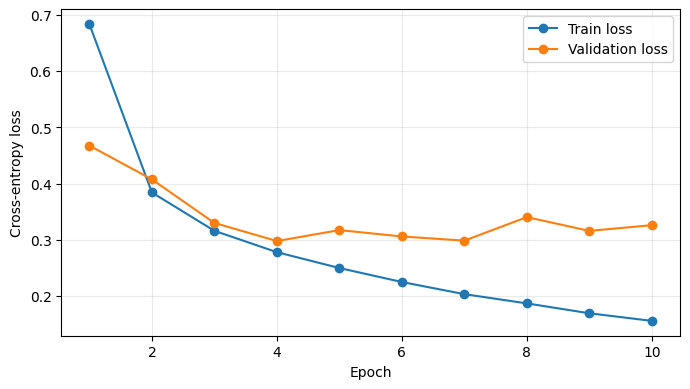

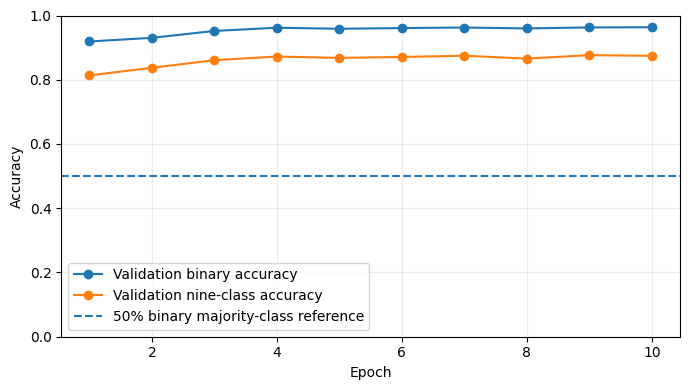

In [34]:
h=pd.read_csv(OUT_DIR/'m0_history.csv')
plt.figure(figsize=(7,4));plt.plot(h.epoch,h.train_loss,marker='o',label='Train loss');plt.plot(h.epoch,h.val_loss,marker='o',label='Validation loss');plt.xlabel('Epoch');plt.ylabel('Cross-entropy loss');plt.legend();plt.grid(alpha=.25);plt.tight_layout();plt.savefig(OUT_DIR/'m0_loss_curve.png',dpi=180);plt.show()
plt.figure(figsize=(7,4));plt.plot(h.epoch,h.val_binary_accuracy,marker='o',label='Validation binary accuracy');plt.plot(h.epoch,h.val_nine_class_accuracy,marker='o',label='Validation nine-class accuracy');plt.axhline(.5,linestyle='--',label='50% binary majority-class reference');plt.xlabel('Epoch');plt.ylabel('Accuracy');plt.ylim(0,1);plt.legend();plt.grid(alpha=.25);plt.tight_layout();plt.savefig(OUT_DIR/'m0_accuracy_curve.png',dpi=180);plt.show()


## Cell 13 — Best-checkpoint validation report


In [35]:
checkpoint=torch.load(OUT_DIR/'m0_best.pt',map_location=DEVICE,weights_only=False)
model=build_m0(pretrained=False).to(DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
metrics,y9,p9=evaluate(model,val_loader,nn.CrossEntropyLoss())
pred9=p9.argmax(1);ybin=(y9!=0).astype(int);predbin=(1-p9[:,0]>=0.5).astype(int)
print('Best epoch:',checkpoint['epoch']);print(json.dumps(metrics,indent=2))
print('9-class report:\n',classification_report(y9,pred9,target_names=CLASS_NAMES,zero_division=0))
print('Binary confusion matrix [real, AI]:\n',confusion_matrix(ybin,predbin,labels=[0,1]))
print('Nine-class confusion matrix:\n',confusion_matrix(y9,pred9,labels=list(range(9))))
(OUT_DIR/'m0_validation_metrics.json').write_text(json.dumps({'best_epoch':checkpoint['epoch'],**metrics},indent=2))
pd.DataFrame(classification_report(y9,pred9,target_names=CLASS_NAMES,zero_division=0,output_dict=True)).T.to_csv(OUT_DIR/'m0_per_class_metrics.csv')


Validation:   0%|          | 0/250 [00:00<?, ?it/s]

Best epoch: 10
{
  "loss": 0.32632074100751196,
  "binary_accuracy": 0.963375,
  "binary_macro_f1": 0.9633707670342654,
  "binary_auc": 0.9944290390625,
  "nine_class_accuracy": 0.8744375,
  "nine_class_macro_f1": 0.8010886717349178
}
9-class report:
               precision    recall  f1-score   support

        Real       0.95      0.98      0.96      8000
         ADM       0.98      0.99      0.98      1000
      BigGAN       0.99      0.99      0.99      1000
       GLIDE       0.97      0.97      0.97      1000
  Midjourney       0.91      0.79      0.85      1000
        SD14       0.41      0.32      0.36      1000
        SD15       0.43      0.48      0.45      1000
        VQDM       0.98      0.94      0.96      1000
      Wukong       0.67      0.69      0.68      1000

    accuracy                           0.87     16000
   macro avg       0.81      0.79      0.80     16000
weighted avg       0.87      0.87      0.87     16000

Binary confusion matrix [real, AI]:
 [[7793

## Cell 14 — Approximate inference latency and model size


In [36]:
import statistics
cpu_model=build_m0(pretrained=False).cpu().eval()
cpu_model.load_state_dict(checkpoint['model_state_dict'])
example=torch.randn(1,3,IMG_SIZE,IMG_SIZE)
old_threads=torch.get_num_threads();torch.set_num_threads(min(4,old_threads))
with torch.inference_mode():
    for _ in range(20): cpu_model(example)
    timings=[]
    for _ in range(100):
        t0=time.perf_counter();cpu_model(example);timings.append((time.perf_counter()-t0)*1000)
torch.set_num_threads(old_threads)
model_size_mb=(OUT_DIR/'m0_best.pt').stat().st_size/1e6
perf={'cpu_median_latency_ms_batch1':float(np.median(timings)),
      'cpu_p90_latency_ms_batch1':float(np.percentile(timings,90)),
      'checkpoint_size_mb':model_size_mb,'cpu':platform.processor(),
      'cpu_threads_used':min(4,old_threads),'input_size':IMG_SIZE,
      'latency_excludes_preprocessing':True}
print(json.dumps(perf,indent=2))
(OUT_DIR/'m0_efficiency.json').write_text(json.dumps(perf,indent=2))


{
  "cpu_median_latency_ms_batch1": 10.575257500022417,
  "cpu_p90_latency_ms_batch1": 11.72585400017852,
  "checkpoint_size_mb": 6.242647,
  "cpu": "x86_64",
  "cpu_threads_used": 1,
  "input_size": 256,
  "latency_excludes_preprocessing": true
}


247

## Checklist before Milestone 2 report
- [✓] Overfit-one-batch reached ≥95% accuracy (ideally 100%).
- [✓] Trained **M0** on 100k training images; saved `m0_best.pt`.
- [✓] Recorded ImageNet pretrained initialization, seed, optimizer, epochs, batch size, hardware.
- [✓] Saved train/validation loss and validation accuracy curves.
- [✓] Reported binary accuracy, macro-F1, AUC; secondary nine-class metrics.
- [✓] Reported parameters, estimated MACs, model size, and batch-1 CPU latency.
- [✓] Did **not** use test.csv for tuning or evaluation.
- [✓] Uploaded notebook, configuration, plots, metrics, and split manifests to GitHub (avoid committing full images or large checkpoint files).